# Customer Clustering with K-Means

This notebook uses `data/customers_cluster.csv`: 1000 customers. There is no group label.

Clustering is unsupervised. The model is not given a label to predict. It only sees annual income, spending score, and age, and it groups customers who look alike on those three numbers.

The steps are:

1. Look at the table and check for missing values or duplicate rows.
2. Plot the customers. Separate clouds, and no label column, mean the task is clustering.
3. Scale the three features so each one counts equally.
4. Use the elbow curve and the silhouette score to choose the number of clusters.
5. Fit k-means with that number.
6. Check the fit with the silhouette score and the cluster centers.
7. Plot the customers again, with each cluster in its own color.


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Keep the plots in the notebook, and use a simple grid style.
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
%matplotlib inline


## Load the data

`Customer_ID` only identifies a row. The three numeric columns are the inputs. There is no target column, because a clustering model does not predict a known answer.


In [2]:
# The notebook lives in Demo/, so the CSV is one folder up.
# The second path is a fallback if this cell is run from the project root.
path = Path("../data/customers_cluster.csv")
if not path.exists():
    path = Path("data/customers_cluster.csv")

customers = pd.read_csv(path)

print("Rows and columns:", customers.shape)
customers.head()


Rows and columns: (1000, 4)


,Customer_ID,Annual_Income,Spending_Score,Age
0,C0001,683,53,39
1,C0002,984,86,47
2,C0003,274,32,24
3,C0004,654,45,44
4,C0005,1011,81,48


## Check for missing values and duplicate rows

K-means needs a number in every column, so a blank cell cannot be used. A repeated row would be counted twice and would pull a cluster center toward that customer.

This file was built with no blanks and no repeated rows. The checks below confirm that. If a blank or a duplicate ever shows up, those two lines drop it.


In [3]:
# Count blanks and repeated rows before any cleaning.
print("Missing values before:")
print(customers.isna().sum())
print("Duplicate rows before:", int(customers.duplicated().sum()))

rows_before = len(customers)
customers = customers.drop_duplicates()
customers = customers.dropna().reset_index(drop=True)

print()
print("Rows before:", rows_before)
print("Rows after:", len(customers))
print("Missing values left:", int(customers.isna().sum().sum()))
print("Duplicate rows left:", int(customers.duplicated().sum()))


Missing values before:
Customer_ID       0
Annual_Income     0
Spending_Score    0
Age               0
dtype: int64
Duplicate rows before: 0

Rows before: 1000
Rows after: 1000
Missing values left: 0
Duplicate rows left: 0


## Exploratory check

The summary shows how wide each feature is. The scatter plots then show whether the customers sit in one cloud or in a few separate clouds.

There is still no column that says which group a customer belongs to. If the dots form separate clouds, the job is to find those groups. That is clustering.


In [4]:
# Column types, then a simple summary of the three numeric columns.
print(customers.dtypes)
print()
customers[["Annual_Income", "Spending_Score", "Age"]].describe()


Customer_ID       object
Annual_Income      int64
Spending_Score     int64
Age                int64
dtype: object



,Annual_Income,Spending_Score,Age
count,1000.000000,1000.000000,1000.000000
mean,652.019000,54.951000,36.778000
std,307.216394,22.876055,9.822892
min,222.000000,17.000000,18.000000
25%,341.750000,33.000000,27.000000
50%,595.000000,51.000000,39.000000
75%,994.500000,80.250000,45.000000
max,1274.000000,99.000000,61.000000


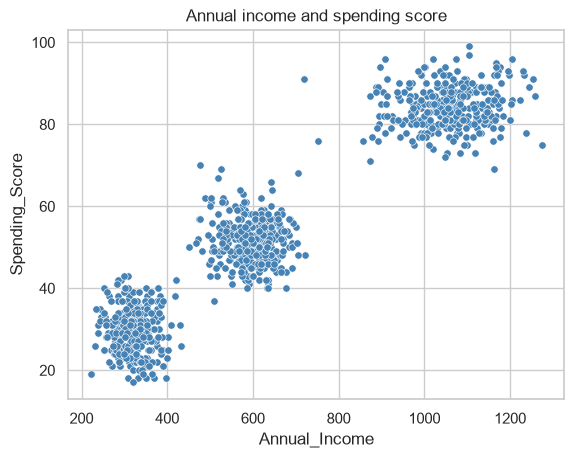

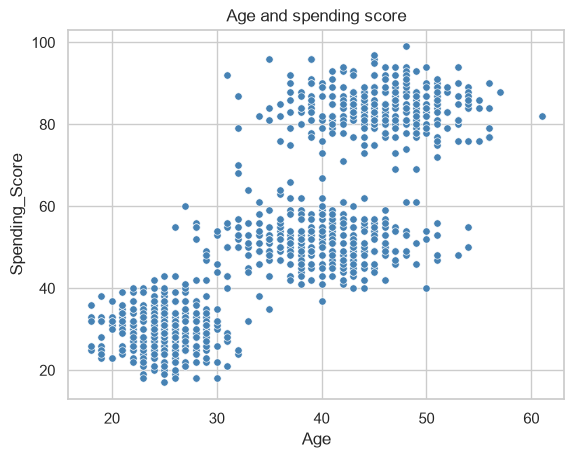

In [5]:
# Each dot is one customer. Separate clouds mean the customers already
# fall into groups, even though the file has no group label.
sns.scatterplot(data=customers, x="Annual_Income", y="Spending_Score", color="steelblue", s=28)
plt.title("Annual income and spending score")
plt.show()

sns.scatterplot(data=customers, x="Age", y="Spending_Score", color="steelblue", s=28)
plt.title("Age and spending score")
plt.show()


The dots are not one even cloud. Income against spending score shows a few separate groups. The file has no label to predict, so the next step is k-means clustering, not classification.


## Scale the features

`Customer_ID` is not a feature. The other three columns are the only inputs. Every row is used. There is no train/test split and no label.

K-means groups points by distance. Annual income runs into the thousands, while spending score stays between 1 and 100 and age stays under 70. Without scaling, income would dominate the distance and the other two columns would barely matter. `StandardScaler` puts each column on a similar scale before the distances are computed.


In [6]:
# Keep only the three numeric columns. The id is not used by the model.
feature_columns = ["Annual_Income", "Spending_Score", "Age"]
X = customers[feature_columns]

# Fit the scaler on these columns and transform them in one step.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Rows used for clustering:", X_scaled.shape[0])
print("Features:", X_scaled.shape[1])


Rows used for clustering: 1000
Features: 3


## Elbow curve

K-means needs k, the number of groups, before it starts. That number is not in the file.

Inertia is how far the customers sit from their own cluster center. It always falls as k grows, because smaller groups fit more tightly. The useful point is the elbow: the bend where extra clusters stop helping much. That bend is the k to use.


1 3000.0
2 962.6
3 295.7
4 237.3
5 184.7
6 166.3
7 149.1
8 134.7


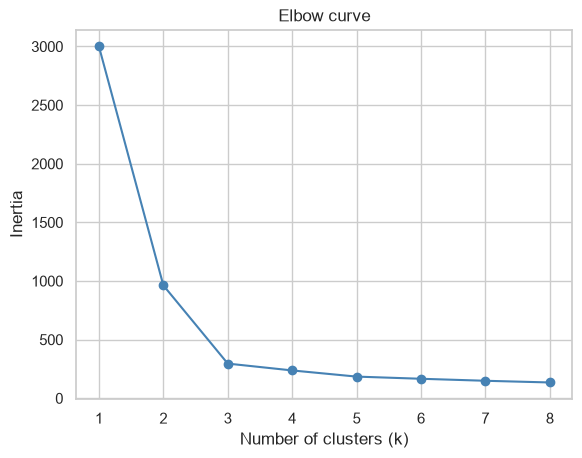

In [7]:
# Fit k-means once for each k and keep the inertia.
ks = range(1, 9)
inertias = []

for k in ks:
    trial = KMeans(n_clusters=k, n_init=10, random_state=42)
    trial.fit(X_scaled)
    inertias.append(trial.inertia_)

for k, inertia in zip(ks, inertias):
    print(k, round(inertia, 1))

# The bend in this line is the k to keep.
plt.plot(list(ks), inertias, marker="o", color="steelblue")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow curve")
plt.xticks(list(ks))
plt.show()


The line drops sharply until k = 3, then flattens. Three is the candidate. The silhouette score is the second check.


## Silhouette score

The silhouette score runs from -1 to 1. A score near 1 means customers are close to their own group and far from the other groups. A score near 0 means the groups overlap.

The loop below scores k from 2 to 8. The highest score is the k to use. K = 1 is skipped, because a single group has no other group to compare against.


2 0.599
3 0.671
4 0.577
5 0.483
6 0.345
7 0.322
8 0.295


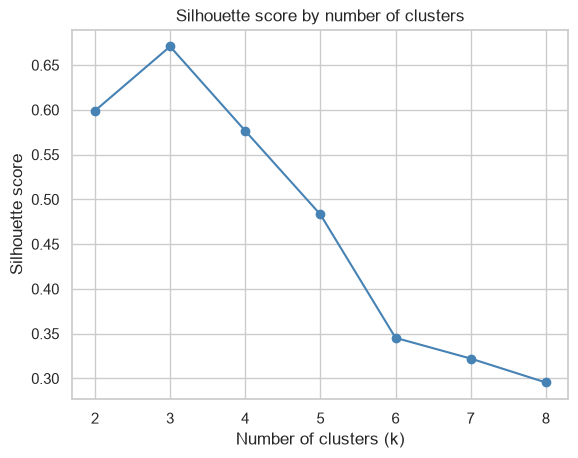

In [8]:
# Score each k. The highest score is the clearest split.
ks = range(2, 9)
scores = []

for k in ks:
    trial = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = trial.fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels))

for k, score in zip(ks, scores):
    print(k, round(score, 3))

plt.plot(list(ks), scores, marker="o", color="steelblue")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score by number of clusters")
plt.xticks(list(ks))
plt.show()


The silhouette score is highest at k = 3. That matches the elbow, so the model is fit with 3 clusters.


## Fit k-means

K-means places 3 centers, assigns every customer to the nearest center, then moves each center to the middle of its customers. It repeats those two steps until the centers stop moving.

The cluster numbers (0, 1, 2) are only ids. They do not mean "better" or "worse" until the centers are read in the original units.


In [9]:
# Fit the final model and store each customer's cluster id.
k = 3
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
customers["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customers in each cluster:")
print(customers["Cluster"].value_counts().sort_index())


Customers in each cluster:
Cluster
0    326
1    335
2    339
Name: count, dtype: int64


## Evaluation

Two checks on the fitted model:

- **Silhouette score** for the chosen k. A score near 1 means the groups are cleanly separated.
- **Cluster centers** are the average customer in each group, turned back into income, spending score, and age. A useful clustering has a different kind of customer in each row.


In [10]:
# One score for the fitted 3-cluster model.
score = silhouette_score(X_scaled, customers["Cluster"])
print("Silhouette score:", round(score, 3))

# The model was fit on scaled columns. inverse_transform puts the
# centers back into income, spending score, and age.
centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=feature_columns,
)
centers.insert(0, "Cluster", range(k))
centers = centers.round(2)

print()
print("Cluster centers:")
centers


Silhouette score: 0.671

Cluster centers:


,Cluster,Annual_Income,Spending_Score,Age
0,0,1053.20,84.27,45.85
1,1,319.58,29.82,24.95
2,2,594.75,51.59,39.74


## Clusters on a scatter plot

The same two views as the exploratory plots, now colored by the cluster k-means assigned. Each color is one group.


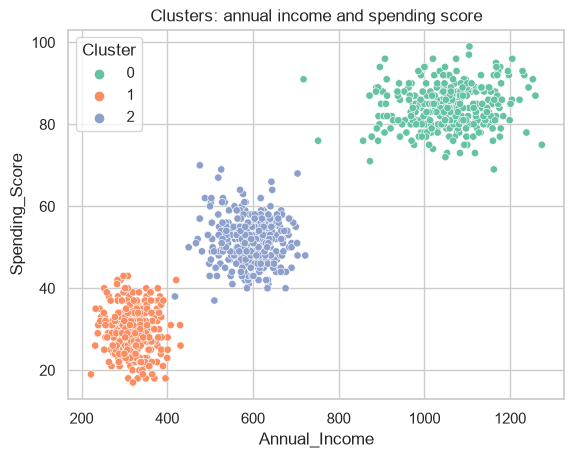

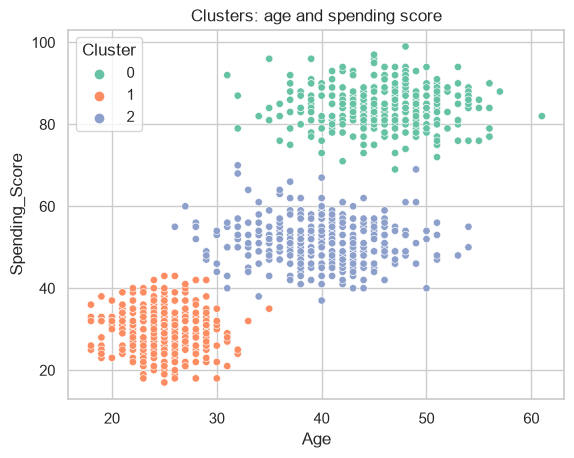

In [11]:
# Color each customer by the cluster id from k-means.
sns.scatterplot(
    data=customers,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="Set2",
    s=28,
)
plt.title("Clusters: annual income and spending score")
plt.show()

sns.scatterplot(
    data=customers,
    x="Age",
    y="Spending_Score",
    hue="Cluster",
    palette="Set2",
    s=28,
)
plt.title("Clusters: age and spending score")
plt.show()


## Takeaways

The elbow bends at 3, and the silhouette score is highest at 3 (about 0.67), so the model is fit with 3 clusters. That score means the groups are cleanly separated.

Reading the centers in the original units gives three kinds of customer:

- One group is young, with lower income and a lower spending score.
- One group is around age 40, with middle income and a middle spending score.
- One group is a bit older, with high income and a high spending score.

The cluster id attached to each kind of customer can change if the model is restarted with a different `random_state`. The three patterns are what the evaluation is for, not the particular numbers 0, 1, and 2.
